# Lecture 2: The Basic RBC Model in Continuous Time

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/02_rbc_continuous_time.ipynb)

**Economics 210A: Macroeconomics** · Johannes Wieland

We now build the simplest model that could generate the facts of Lecture 1: a frictionless economy with a representative household and a representative firm, competitive markets, and shocks to productivity. The model, in the spirit of [Kydland and Prescott (1982)](https://www.jstor.org/stable/1913386), is obviously unrealistic, but it is the benchmark that every later model modifies.

We work in **continuous time**. It is the natural setting for the phase diagrams we use in Lecture 3 to understand the model's comparative statics, and it avoids the timing ambiguities that arise when a discrete-time model is analyzed graphically. This lecture sets up the model, solves for its steady state, log-linearizes it, calibrates it, and solves the linearized model. Every step is checked in code. At the end we verify the linearized solution against the exact nonlinear transition.

## Readings

- King, R. G., C. I. Plosser, and S. T. Rebelo (1988), "[Production, Growth and Business Cycles: I. The Basic Neoclassical Model](https://doi.org/10.1016/0304-3932%2888%2990030-X)," *Journal of Monetary Economics* 21(2–3).
- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.3386/w7534)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.
- Kydland, F. E. and E. C. Prescott (1982), "[Time to Build and Aggregate Fluctuations](https://www.jstor.org/stable/1913386)," *Econometrica* 50(6).
- Blanchard, O. J. and C. M. Kahn (1980), "[The Solution of Linear Difference Models under Rational Expectations](https://doi.org/10.2307/1912186)," *Econometrica* 48(5).

## Setup

The model code lives in [`code/rbc_ct.py`](../code/rbc_ct.py): steady state, nonlinear equations, linearization, saddle-path solution, and a nonlinear solver.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rbc_ct as rbc
from bcdata import COLORS, set_plot_style

set_plot_style()
pd.set_option("display.precision", 3)

## 1. Households

A representative household chooses consumption $C_t$ and hours $L_t$ to maximize lifetime utility

$$
\max_{\{C_t, L_t\}} \int_0^\infty e^{-\rho t} \left( \ln C_t - \frac{L_t^{1+1/\eta}}{1+1/\eta} \right) dt
\qquad \text{s.t.} \qquad \dot A_t = r_t A_t + W_t L_t - C_t,
\tag{HH}
$$

and the no-Ponzi condition $\lim_{t\to\infty} e^{-\int_0^t r_s ds} A_t \ge 0$. Here $A_t$ is wealth, $r_t$ the real interest rate, $W_t$ the real wage, and $\rho$ the rate of time preference. Time subscripts mark variables; symbols without them ($\rho$, $\eta$, $\alpha$, $\delta$) are parameters. Log utility in consumption matches the fact that hours show no trend despite large long-run increases in wages: income and substitution effects of permanent wage increases cancel.

The current-value Hamiltonian (see the aside at the end of this section for its relation to the Lagrangian) is

$$
\mathcal H_t = \ln C_t - \frac{L_t^{1+1/\eta}}{1+1/\eta} + \lambda_t \left( r_t A_t + W_t L_t - C_t \right),
$$

where the co-state $\lambda_t$ is the **marginal utility of wealth**. The optimality conditions are

$$
\begin{aligned}
\frac{\partial \mathcal H_t}{\partial C_t} = 0: &\qquad \frac{1}{C_t} = \lambda_t, \\
\frac{\partial \mathcal H_t}{\partial L_t} = 0: &\qquad L_t^{1/\eta} = \lambda_t W_t, \\
\dot\lambda_t = \rho\lambda_t - \frac{\partial \mathcal H_t}{\partial A_t}: &\qquad \frac{\dot\lambda_t}{\lambda_t} = \rho - r_t,
\end{aligned}
\tag{HH-FOC}
$$

together with the transversality condition

$$
\lim_{t\to\infty} e^{-\rho t}\lambda_t A_t = 0 .
\tag{HH-TVC}
$$

**Labor supply.** $L_t = (\lambda_t W_t)^{\eta}$. Holding $\lambda_t$ fixed, $\partial \ln L_t / \partial \ln W_t = \eta$: this is the **Frisch elasticity** of labor supply. Changes in $\lambda_t$ are wealth effects that shift labor supply: when the household is poorer (higher $\lambda_t$), it works more at any given wage. Eliminating $\lambda_t$ gives the intratemporal condition

$$
L_t^{1/\eta} = \frac{W_t}{C_t}.
\tag{LS}
$$

**Euler equation.** Since $\lambda_t = 1/C_t$,

$$
\frac{\dot C_t}{C_t} = r_t - \rho .
\tag{EE}
$$

Consumption grows when the interest rate exceeds the discount rate. This is the continuous-time version of $1/C_t = \beta(1+r_{t+1})/C_{t+1}$, with $\beta = e^{-\rho}$.

**$\lambda_t$ is forward looking.** Integrating the Euler equation forward, $\lambda_t = \lambda_s e^{\int_t^s (\rho - r_u)\,du}$ for any $s > t$: today's marginal utility of wealth depends on the whole future path of interest rates. A *transitory* shock that moves $r_t$ only briefly therefore moves $\lambda_t$ little, so labor supply barely shifts. A *permanent* shock changes the long-run level of wealth and can move $\lambda_t$ a lot.

---

**Aside: the Hamiltonian and the Lagrangian.** The Hamiltonian is defined at each instant; the integral over time belongs to the Lagrangian of the whole problem. Write $u_t$ for flow utility and $g_t = r_t A_t + W_t L_t - C_t$ for the budget constraint, and attach a multiplier $e^{-\rho t}\lambda_t$ to the constraint at each date:

$$
\mathcal L = \int_0^\infty e^{-\rho t}\left[u_t + \lambda_t\left(g_t - \dot A_t\right)\right]dt .
$$

Integrating the term in $\dot A_t$ by parts, $-\int_0^\infty e^{-\rho t}\lambda_t \dot A_t\,dt = \lambda_0 A_0 - \lim_{t\to\infty} e^{-\rho t}\lambda_t A_t + \int_0^\infty e^{-\rho t}\left(\dot\lambda_t - \rho\lambda_t\right)A_t\,dt$, gives

$$
\mathcal L = \int_0^\infty e^{-\rho t}\left[\mathcal H_t + \left(\dot\lambda_t - \rho\lambda_t\right)A_t\right]dt + \lambda_0 A_0 - \lim_{t\to\infty} e^{-\rho t}\lambda_t A_t ,
$$

with $\mathcal H_t = u_t + \lambda_t g_t$. The controls $C_t$ and $L_t$ appear only in $\mathcal H_t$, so maximizing $\mathcal L$ date by date gives $\partial\mathcal H_t/\partial C_t = \partial\mathcal H_t/\partial L_t = 0$. Setting the derivative with respect to $A_t$ to zero at each $t > 0$ gives $\partial\mathcal H_t/\partial A_t + \dot\lambda_t - \rho\lambda_t = 0$, the co-state equation. $A_0$ is given, and the boundary term at infinity is the transversality condition.

---


## 2. Firms

Firms produce output with the technology

$$
Y_t = Z_t K_t^\alpha L_t^{1-\alpha} .
\tag{PF}
$$

They own the capital stock and invest, so capital accumulates according to

$$
\dot K_t = I_t - \delta K_t ,
\tag{KA}
$$

where $\delta$ is the depreciation rate. Firms maximize the present value of cash flows,

$$
\max_{\{L_t, I_t\}} \int_0^\infty e^{-\int_0^t r_s ds} \left( Z_t K_t^\alpha L_t^{1-\alpha} - W_t L_t - I_t \right) dt
\qquad \text{s.t.} \qquad \dot K_t = I_t - \delta K_t .
$$

Capital $K_t$ is the state variable, and $L_t$ and $I_t$ are the controls. The current-value Hamiltonian, with co-state $q_t$ on the capital accumulation equation, is

$$
\mathcal H^F_t = Z_t K_t^\alpha L_t^{1-\alpha} - W_t L_t - I_t + q_t \left( I_t - \delta K_t \right).
$$

The firm discounts at the market rate $r_t$, so $r_t$ takes the place of $\rho$ in the co-state equation (compare the household's co-state equation in (HH-FOC)). The optimality conditions are

$$
\begin{aligned}
\frac{\partial \mathcal H^F_t}{\partial L_t} = 0: &\qquad (1-\alpha) Z_t K_t^\alpha L_t^{-\alpha} = W_t, \\
\frac{\partial \mathcal H^F_t}{\partial I_t} = 0: &\qquad q_t = 1, \\
\dot q_t = r_t q_t - \frac{\partial \mathcal H^F_t}{\partial K_t}: &\qquad \dot q_t = r_t q_t - \left( \alpha Z_t K_t^{\alpha-1} L_t^{1-\alpha} - \delta q_t \right),
\end{aligned}
\tag{F-FOC}
$$

together with the transversality condition

$$
\lim_{t\to\infty} e^{-\int_0^t r_s ds} q_t K_t = 0 .
\tag{F-TVC}
$$

Using $Y_t = Z_t K_t^\alpha L_t^{1-\alpha}$, these become

$$
\begin{aligned}
W_t &= (1-\alpha)\frac{Y_t}{L_t} = MPL_t \\
q_t &= 1 \\
\dot q_t &= (r_t+\delta) q_t - \alpha\frac{Y_t}{K_t}.
\end{aligned}
$$

If $q_t > 1$, the real marginal cost of a unit of capital ($=1$) is less than the real marginal value of capital, and firms can increase profits by increasing investment. Conversely, if $q_t < 1$, the real marginal cost of a unit of capital ($=1$) exceeds the real marginal value of capital, and firms can increase profits by reducing investment. Maximizing profits therefore require firms to choose investment until $q_t = 1$, where the marginal value of a unit of installed capital equals its purchase price.

The co-state $q_t$ is **Tobin's $q$**, the marginal value of installed capital. Solving its law of motion forward, 

$$
q_t = \int_t^\infty e^{-\int_t^s (r_u+\delta)\,du} \alpha\frac{Y_s}{K_s}\, ds
$$.

This is the expected discounted extra output produced from an extra unit of capital $K_t$.

Without adjustment costs, firms invest until $q_t = 1$, so $\dot q_t = 0$ and

$$
r_t + \delta = \alpha \frac{Y_t}{K_t} = MPK_t .
\tag{KD}
$$

This equation says that the **marginal product on capital** (MPK) is equal to the cost of using capital $\delta + r_t$ which is the *gross* return of capital since it also includes the term due to depreciation of capital ($\delta$). In effect, the firm trades off buying a unit of capital now (cost $1$), earning the marginal product $MPK$, and selling the unit of capital net of depreciation $1-\delta$, with the opportunity cost, which is earning $1+r_t$. At the optimum investment the firm must be indifferent.

The FOC for $L_t$ is the demand for labor:
$$
W_t = (1-\alpha) \frac{Y_t}{L_t}=(1-\alpha) Z_t L_t^{-\alpha}K_{t}^{\alpha} = MPL_t  
\tag{LD}
$$
$MPL_t$ is the **marginal product of labor** (MPL). The firm hires workers until the MPL equals the market wage. Note that because output has decreasing returns to scale in labor, the MPL (and hence the labor demand curve) is downward sloping in labor. 

Below are example plots of the labor and capital demand curves. Given a real wage and real interest rate, these pin down the optimal quantity of labor and capital respectively.

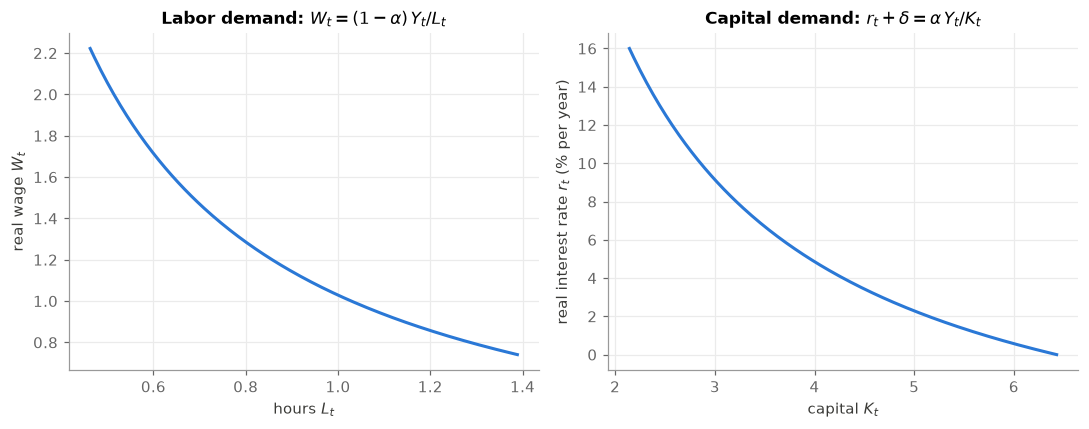

In [2]:
p = rbc.Params()
ss = rbc.steady_state(p)
Y = ss["Y"]                                         # output (and Z) held at steady-state values
Lg = np.linspace(0.5, 1.5, 200) * ss["L"]
Kg = np.linspace(0.5, 1.5, 200) * ss["K"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(Lg, (1 - p.alpha) * Y / Lg, color=COLORS["gdp"], lw=2)
ax.set_xlabel(r"hours $L_t$"); ax.set_ylabel(r"real wage $W_t$")
ax.set_title(r"Labor demand: $W_t = (1-\alpha)\,Y_t/L_t$")

ax = axes[1]
ax.plot(Kg, 100 * (p.alpha * Y / Kg - p.delta), color=COLORS["gdp"], lw=2)
ax.set_xlabel(r"capital $K_t$"); ax.set_ylabel(r"real interest rate $r_t$ (% per year)")
ax.set_title(r"Capital demand: $r_t + \delta = \alpha\,Y_t/K_t$")
plt.tight_layout()


## 3. Competitive equilibrium

**Definition.** Given the initial capital stock $K_0$ and a path of technology $\{Z_t\}_{t\ge 0}$, a **competitive equilibrium** is a path of quantities $\{C_t, L_t, L^s_t, L^d_t, A_t, K_t, I_t, Y_t\}_{t\ge0}$ and prices $\{W_t, r_t, q_t\}_{t\ge0}$ such that

1. households maximize utility taking prices as given: the optimality conditions (HH-FOC) and the transversality condition (HH-TVC) hold, which imply the intratemporal condition (LS) with labor supply $L^s_t$ and the Euler equation (EE);
2. firms maximize the present value of cash flows taking prices as given: the optimality conditions (F-FOC) and the transversality condition (F-TVC) hold, which imply labor demand (LD) with $L_t = L^d_t$ and capital demand (KD);
3. the technological constraints hold: the production function (PF) and capital accumulation (KA);
4. all markets clear (MC):

$$
\begin{aligned}
L^s_t &= L^d_t = L_t && \text{(labor market)} \\
A_t &= q_t K_t = K_t && \text{(capital market)} \\
Y_t &= C_t + I_t && \text{(goods market)}
\end{aligned}
\tag{MC}
$$

The labor market condition equates labor supply and demand. The capital market condition says that the household's wealth equals the value of the firms it owns, $q_t K_t$, which is $K_t$ since $q_t = 1$. Holding firm shares earns the market rate: dividends $Y_t - W_t L_t - I_t = r_t K_t - \dot K_t$ plus capital gains $\dot K_t$ add up to $r_t K_t$. By **Walras' law** only two of the three market-clearing conditions are needed: combining the household budget constraint (HH) with $A_t = K_t$ and the firm's optimality conditions gives goods market clearing. The economy is closed and there is no government.

**Technology.** Log TFP follows the continuous-time analogue of an AR(1) process,

$$
\frac{\dot Z_t}{Z_t} = -\theta \ln Z_t ,
\tag{TFP}
$$

so that $\ln Z_t = e^{-\theta t}\ln Z_0$: after a disturbance, technology returns to its steady-state level $\bar Z = 1$ at rate $\theta$. Time $t$ is measured in years, so $\theta$ is an annual rate: a discrete-time quarterly persistence $\rho_z$ corresponds to $\theta = -4\ln \rho_z$. Since our focus is business cycles, we ignore trend growth in productivity.

**Recap.** We can now summarize the economy with the following system of equations:

$$
\begin{aligned}
C_t L_t^{1/\eta} &= (1-\alpha)\frac{Y_t}{L_t} = W_t && \text{(labor market)} \\
\frac{\dot C_t}{C_t} &= r_t - \rho = \alpha\frac{Y_t}{K_t} - \delta - \rho && \text{(Euler equation)} \\
Y_t &= Z_t K_t^\alpha L_t^{1-\alpha} && \text{(production function)} \\
Y_t &= C_t + I_t && \text{(goods market)} \\
\dot K_t &= I_t - \delta K_t && \text{(capital accumulation)} \\
\frac{\dot Z_t}{Z_t} &= -\theta \ln Z_t && \text{(technology)}
\end{aligned}
\tag{EQ}
$$

## 4. The steady state

To understand how the economy fluctuates, we first find the values the variables take when the economy is not perturbed by shocks. The **steady state** is an equilibrium in which all variables are constant over time: $\dot K_t = \dot C_t = 0$ and $Z_t = \bar Z$. The steady-state value of a variable $X_t$ is denoted $\bar X$. The equilibrium describes how the economy moves over time from *any* initial capital stock; the steady state is the point it comes to rest at in the absence of shocks.

From the recap (EQ), the steady state is characterized by

$$
\begin{aligned}
\bar C \bar L^{1/\eta} &= (1-\alpha)\frac{\bar Y}{\bar L}, \\
0 &= \alpha\frac{\bar Y}{\bar K} - \delta - \rho, \\
\bar Y &= \bar Z \bar K^\alpha \bar L^{1-\alpha}, \\
\bar Y &= \bar C + \bar I, \\
0 &= \bar I - \delta\bar K, \\
\bar Z &= 1 .
\end{aligned}
\tag{SS}
$$

We now solve for the steady-state values. Immediately, from the production function, capital accumulation and technology:

$$
\begin{aligned}
\bar I &= \delta\bar K, \\
\bar Z &= 1, \\
\bar Y &= \bar K^\alpha \bar L^{1-\alpha}.
\end{aligned}
$$

The Euler equation gives $\bar r = \rho$, and so pins down the capital–labor ratio:

$$
\begin{aligned}
\rho + \delta &= \alpha\frac{\bar Y}{\bar K} \\
\rho + \delta &= \alpha\left(\frac{\bar K}{\bar L}\right)^{\alpha-1} \\
\kappa \equiv \frac{\bar K}{\bar L} &= \left(\frac{\alpha}{\rho+\delta}\right)^{\frac{1}{1-\alpha}} \\
\bar K &= \kappa\,\bar L ,
\end{aligned}
$$

where $\kappa$ depends only on parameters. The labor market condition gives consumption:

$$
\begin{aligned}
\bar C &= (1-\alpha)\,\bar L^{-1/\eta}\,\frac{\bar Y}{\bar L} \\
\bar C &= (1-\alpha)\,\bar L^{-1/\eta}\,\kappa^\alpha .
\end{aligned}
$$

Next, we substitute the expressions for $\bar Y$, $\bar C$ and $\bar I = \delta\bar K$ as functions of $\bar L$ into the goods market condition $\bar Y = \bar C + \delta\bar K$:

$$
\kappa^\alpha \bar L = (1-\alpha)\,\bar L^{-1/\eta}\,\kappa^\alpha + \delta\kappa\,\bar L .
$$

Collecting the terms in $\bar L$,

$$
\begin{aligned}
\bar L^{1+1/\eta} &= \frac{(1-\alpha)\,\kappa^\alpha}{\kappa^\alpha - \delta\kappa} = \frac{1-\alpha}{1 - \delta\kappa^{1-\alpha}} \\
\bar L &= \left(\frac{1-\alpha}{\bar C/\bar Y}\right)^{\frac{\eta}{1+\eta}},
\end{aligned}
$$

where we used $\delta\kappa^{1-\alpha} = \delta\bar K/\bar Y = \bar I/\bar Y$, so that $1 - \delta\kappa^{1-\alpha} = \bar C/\bar Y$. The great ratios also depend only on parameters:

$$
\frac{\bar K}{\bar Y} = \frac{\alpha}{\rho+\delta}, \qquad
\frac{\bar I}{\bar Y} = \frac{\delta\alpha}{\rho+\delta}, \qquad
\frac{\bar C}{\bar Y} = 1 - \frac{\delta\alpha}{\rho+\delta}.
\tag{GR}
$$

Next we log-linearize around the steady-state.


## 5. Log-linearization

Nonlinear systems are hard to analyze. For small perturbations, linear approximations capture the dynamics of the model well and are easy to analyze. We linearize the system around the steady state and work with **log deviations** from the steady state,

$$
\hat x_t = \ln\left(\frac{X_t}{\bar X}\right) \approx \frac{X_t - \bar X}{\bar X} = \frac{dX_t}{\bar X},
$$

Two facts are useful. First, writing $X_t = \bar X e^{\hat x_t}$, a first-order approximation gives $X_t \approx \bar X\left(1 + \hat x_t\right)$. Second, the time derivative of a log deviation is a growth rate, $\dot{\hat x}_t = \dot X_t/X_t$. We now derive the log-linearized equations one at a time.

**Goods market.** Totally differentiate $Y_t = C_t + I_t$ around the steady state and divide by $\bar Y$:

$$
\begin{aligned}
Y_t &= C_t + I_t \\
dY_t &= dC_t + dI_t \\
\frac{dY_t}{\bar Y} &= \frac{\bar C}{\bar Y}\frac{dC_t}{\bar C} + \frac{\bar I}{\bar Y}\frac{dI_t}{\bar I} \\
\hat y_t &= \frac{\bar C}{\bar Y}\hat c_t + \frac{\bar I}{\bar Y}\hat\imath_t \\
\hat y_t &= \left(1 - \frac{\bar I}{\bar Y}\right)\hat c_t + \frac{\bar I}{\bar Y}\hat\imath_t ,
\end{aligned}
$$

where $\bar I/\bar Y = \delta\alpha/(\rho+\delta)$ from the great ratios (GR).

**Capital accumulation.** Divide $\dot K_t = I_t - \delta K_t$ by $K_t$, so that the left-hand side is $\dot{\hat k}_t$, and use $\bar I/\bar K = \delta$:

$$
\begin{aligned}
\frac{\dot K_t}{K_t} &= \frac{I_t}{K_t} - \delta \\
\dot{\hat k}_t &= \frac{\bar I}{\bar K}\,\frac{I_t/\bar I}{K_t/\bar K} - \delta \\
\dot{\hat k}_t &= \delta\left(e^{\hat\imath_t - \hat k_t} - 1\right) \\
\dot{\hat k}_t &\approx \delta\left(\hat\imath_t - \hat k_t\right).
\end{aligned}
$$

**Production function.** Take logs of $Y_t = Z_t K_t^\alpha L_t^{1-\alpha}$ and subtract the same equation in steady state. Since the equation is log-linear, this is exact:

$$
\begin{aligned}
\ln Y_t &= \ln Z_t + \alpha\ln K_t + (1-\alpha)\ln L_t \\
\ln Y_t - \ln\bar Y &= \left(\ln Z_t - \ln\bar Z\right) + \alpha\left(\ln K_t - \ln\bar K\right) + (1-\alpha)\left(\ln L_t - \ln\bar L\right) \\
\hat y_t &= \hat z_t + \alpha\hat k_t + (1-\alpha)\hat l_t .
\end{aligned}
$$

**Labor market.** The same steps applied to $C_t L_t^{1/\eta} = (1-\alpha)Y_t/L_t$ give

$$
\begin{aligned}
\ln C_t + \frac{1}{\eta}\ln L_t &= \ln(1-\alpha) + \ln Y_t - \ln L_t \\
\hat c_t + \frac{1}{\eta}\hat l_t &= \hat y_t - \hat l_t .
\end{aligned}
$$

**Euler equation.** The left-hand side of $\dot C_t/C_t = \alpha Y_t/K_t - \delta - \rho$ is $\dot{\hat c}_t$. On the right-hand side, approximate the output–capital ratio and use the steady-state condition $\alpha\bar Y/\bar K = \rho + \delta$ from (SS):

$$
\begin{aligned}
\dot{\hat c}_t &= \alpha\frac{Y_t}{K_t} - \delta - \rho \\
\dot{\hat c}_t &= \alpha\frac{\bar Y}{\bar K}\,e^{\hat y_t - \hat k_t} - \delta - \rho \\
\dot{\hat c}_t &\approx \alpha\frac{\bar Y}{\bar K}\left(1 + \hat y_t - \hat k_t\right) - \delta - \rho \\
\dot{\hat c}_t &= (\rho+\delta)\left(\hat y_t - \hat k_t\right).
\end{aligned}
$$

A 1% increase in the output–capital ratio raises the marginal product of capital, and hence the interest rate, by $(\rho+\delta)/100$.

**Technology.** With $\bar Z = 1$, $\hat z_t = \ln Z_t$, so the technology process is already linear: $\dot{\hat z}_t = -\theta\hat z_t$.

Collecting the equations, the log-linearized system is:

$$
\begin{aligned}
\hat y_t &= \left(1 - \frac{\bar I}{\bar Y}\right)\hat c_t + \frac{\bar I}{\bar Y}\hat\imath_t && \text{(goods market)} \\
\dot{\hat k}_t &= \delta\left(\hat\imath_t - \hat k_t\right) && \text{(capital accumulation)} \\
\hat c_t + \frac{1}{\eta}\hat l_t &= \hat y_t - \hat l_t && \text{(labor market)} \\
\dot{\hat c}_t &= (\rho+\delta)\left(\hat y_t - \hat k_t\right) && \text{(Euler equation)} \\
\hat y_t &= \hat z_t + \alpha\hat k_t + (1-\alpha)\hat l_t && \text{(production function)} \\
\dot{\hat z}_t &= -\theta\,\hat z_t && \text{(technology)}
\end{aligned}
\tag{LL}
$$

**Perfect foresight and certainty equivalence.** We study the model under perfect foresight: the path of $Z_t$ is known, except for unanticipated disturbances at $t = 0$ (so-called "MIT shocks"). In a linear model this is without loss of generality. By **certainty equivalence**, agents in a linear rational expectations model behave exactly *as if* they knew that no further shocks would occur. The response to a shock under perfect foresight is therefore the same as the impulse response in the stochastic model.

## 6. Calibration

General equilibrium models rarely have simple analytical solutions, so we study them numerically. That requires values for the parameters. There are two broad strategies.

The first is to **estimate** the model using moments of the data, and then evaluate it using other moments. Although intuitive, this is problematic for a model as simple as ours: it is clearly misspecified, so the estimates can be badly biased. The critique is less compelling for richer models such as [Smets and Wouters (2007)](https://doi.org/10.1257/aer.97.3.586) or [Christiano, Eichenbaum and Evans (2005)](https://doi.org/10.1086/426038), with many variables, shocks, and equations.

The second is to **calibrate**: assign parameter values that are plausible on economic grounds. The trick is to pick moments of the data so that each parameter governs a particular moment, without relying on estimation of the whole model. A misspecification in one equation is then less likely to spill over to other parameters. This was the motivation of [Kydland and Prescott (1982)](https://www.jstor.org/stable/1913386). They envisioned that parameter values would come from **micro**-level studies (e.g., labor supply elasticities estimated from micro data), and the model would then be used to study **macroeconomic** properties. This ideal is not always feasible. For example, the aggregate labor supply elasticity has an extensive margin (how many people work) and an intensive margin (how many hours each person works), while micro studies typically capture only the intensive margin. In some cases we have to rely on macroeconomic data.

We do not want to evaluate the model on the same moments used to calibrate it: a just-identified model fits those perfectly, which is not an informative test. Kydland and Prescott suggested what became standard practice: use **first** moments of the data (means, ratios) to calibrate, and **second** moments (variances, covariances, autocorrelations) to evaluate the model. More generally, one evaluates the model on moments not used in calibration.

**Units.** In continuous time, rates are defined per unit of time. Following the standard convention, we measure time in **years**, so $\rho$, $\delta$, $\theta$ and the interest rate are annual rates, and flows such as $Y_t$, $C_t$ and $I_t$ are per year. The choice of unit is a normalization: measuring time in quarters with all rates divided by four describes the same economy, and impulse responses can be read off at any frequency. We plot them in quarters to compare with the quarterly data of Lecture 1.

- **Capital share $\alpha$.** From the firm's labor demand (LD), the labor share is $W_tL_t/Y_t = 1-\alpha$. In NIPA data it is roughly constant at about 2/3, so $\alpha = 1/3$.
- **Discount rate $\rho$.** In steady state $\bar r = \rho$ (Euler equation (EE)). The real return on a broad stock market portfolio is about 4–6% per year. We set $\rho = 0.04$ (the corresponding quarterly discount factor is $e^{-\rho/4} \approx 0.99$).
- **Depreciation $\delta$.** In steady state $\delta = \bar I/\bar K$. The NIPA investment–capital ratio is about 0.076 per year, so $\delta \approx 0.08$.
- **Frisch elasticity $\eta$.** Important but hard to estimate. Micro estimates are low, between 0 and 0.5. But hours are about as volatile as output, which requires a high elasticity in the model, and the micro estimates likely reflect only the intensive margin. We use $\eta = 1$.
- **Technology.** Fitting an AR(1) to the Solow residual gives quarterly persistence close to one and innovations with standard deviation of about 0.007. We use quarterly persistence $\rho_z = 0.95$, so $\theta = -4\ln 0.95 \approx 0.21$ per year.

**A consistency check.** The steady state (SS) implies $\rho = \alpha\,\bar Y/\bar K - \delta$. In annual data $\bar K/\bar Y \approx 3.3$ and $\delta \approx 0.076$, so with $\alpha = 0.33$ we get $\rho \approx 0.33/3.3 - 0.076 \approx 0.024$, or a quarterly discount factor $e^{-0.024/4} \approx 0.994$. This is broadly consistent with the value obtained from the real rate of return.

| Parameter | Value | Target |
|---|---|---|
| $\alpha$ | 1/3 | labor share $\bar W\bar L/\bar Y = 2/3$ |
| $\rho$ | 0.04 | real rate ≈ 4% per year |
| $\delta$ | 0.08 | investment–capital ratio ≈ 8% per year |
| $\eta$ | 1 | Frisch elasticity |
| $\theta$ | $-4\ln 0.95 \approx 0.21$ | quarterly persistence of TFP 0.95 |

In [3]:
p = rbc.Params()
theta = -4 * np.log(0.95)      # annual rate; TFP persistence 0.95 per quarter
ss = rbc.steady_state(p)
pd.DataFrame({
    "value": [ss["K"] / ss["Y"], ss["I"] / ss["Y"], ss["C"] / ss["Y"], ss["L"], 100 * ss["r"]],
}, index=["K/Y (years)", "I/Y", "C/Y", "L", "r (% per year)"])

,value
K/Y (years),2.778
I/Y,0.222
C/Y,0.778
L,0.926
r (% per year),4.000


The implied capital–output ratio of about 2.8 years and investment share of 22% are in the range of U.S. data.

## 7. Dynamic solution

**Reducing the system.** We reduce the log-linearized system (LL) to two dynamic equations. We use the capital stock $\hat k_t$, a predetermined **state** variable, and the marginal utility of wealth $\hat\lambda_t = -\hat c_t$ (from (HH-FOC)), a forward-looking **jump** variable. Combining the labor market condition with the production function gives hours as a function of the state and technology:

$$
\hat l_t = \varphi\left(\hat\lambda_t + \hat z_t + \alpha \hat k_t\right), \qquad \varphi \equiv \frac{1}{1/\eta + \alpha}.
$$

Hours rise with $\hat\lambda_t$ (a wealth effect on labor supply) and with $\hat z_t$ and $\hat k_t$ (both raise labor demand). Substituting $\hat l_t$ into the production function, investment into capital accumulation, and output into the Euler equation (with $\dot{\hat\lambda}_t = -\dot{\hat c}_t$), we get

$$
\dot{\hat k}_t = \frac{\bar Y}{\bar K}\hat y_t + \frac{\bar C}{\bar K}\hat\lambda_t - \delta \hat k_t,
\qquad
\dot{\hat \lambda}_t = -(\rho + \delta)(\hat y_t - \hat k_t),
$$

with $\hat y_t = \hat z_t + \alpha \hat k_t + (1-\alpha)\hat l_t$. Writing $m \equiv 1 + (1-\alpha)\varphi$ for the elasticity of output with respect to $\hat z_t$ (including the labor response), this is a linear system in $x_t = (\hat k_t, \hat\lambda_t)'$ driven by $\hat z_t$:

$$
\begin{pmatrix} \dot{\hat k}_t \\ \dot{\hat\lambda}_t \end{pmatrix}
=
\underbrace{\begin{pmatrix}
(\rho+\delta) m - \delta & \frac{\bar Y}{\bar K}(1-\alpha)\varphi + \frac{\bar C}{\bar K} \\[4pt]
(\rho+\delta)(1-\alpha)\varphi/\eta & -(\rho+\delta)(1-\alpha)\varphi
\end{pmatrix}}_{A}
\begin{pmatrix} \hat k_t \\ \hat\lambda_t \end{pmatrix}
+
\underbrace{\begin{pmatrix}
\frac{\bar Y}{\bar K} m \\[4pt]
-(\rho+\delta) m
\end{pmatrix}}_{b}
\hat z_t .
\tag{LIN}
$$

In the top-left entry we used $\frac{\bar Y}{\bar K}\alpha = \rho+\delta$. Algebra like this is error-prone, so we check it: the code computes $A$ and $b$ from the formulas above and compares them with a finite-difference Jacobian of the *nonlinear* equations.

In [4]:
A, B = rbc.linear_system(p)
A_num, B_num = rbc.numerical_jacobian(p)
b, b_num = B[:, 0], B_num[:, 0]            # column of the TFP shock
print("A =\n", A.round(4))
print("b =", b.round(4))
print(f"max |analytic - numerical|: A {np.abs(A - A_num).max():.1e},  b {np.abs(b - b_num).max():.1e}")

A =
 [[ 0.1   0.46]
 [ 0.06 -0.06]]
b = [ 0.54 -0.18]
max |analytic - numerical|: A 1.4e-11,  b 6.8e-12


**Method of undetermined coefficients.** With two state variables, capital $\hat k_t$ and technology $\hat z_t$, optimal control theory tells us that the solution takes the form

$$
\hat\lambda_t = \nu_{\lambda k}\,\hat k_t + \nu_{\lambda z}\,\hat z_t, \qquad
\dot{\hat k}_t = \mu_s\,\hat k_t + \nu_{kz}\,\hat z_t .
\tag{POL}
$$

Equivalently, consumption follows $\hat c_t = \nu_{ck}\hat k_t + \nu_{cz}\hat z_t$ with $\nu_{ck} = -\nu_{\lambda k}$ and $\nu_{cz} = -\nu_{\lambda z}$. To find the coefficients, differentiate the guess with respect to time and use $\dot{\hat z}_t = -\theta \hat z_t$:

$$
\dot{\hat\lambda}_t = \nu_{\lambda k}\dot{\hat k}_t + \nu_{\lambda z}\dot{\hat z}_t
= \nu_{\lambda k}\left(A_{11}\hat k_t + A_{12}\hat\lambda_t + b_1\hat z_t\right) - \theta\nu_{\lambda z}\hat z_t ,
$$

where we substituted $\dot{\hat k}_t$ from the linear system (LIN).

By the second row of (LIN), this must equal $A_{21}\hat k_t + A_{22}\hat\lambda_t + b_2\hat z_t$. Substituting the guess for $\hat\lambda_t$ on both sides, the equation must hold for all values of $\hat k_t$ and $\hat z_t$, so the coefficients on each must match:

$$
\begin{aligned}
\hat k_t: &\qquad A_{12}\,\nu_{\lambda k}^2 + (A_{11} - A_{22})\,\nu_{\lambda k} - A_{21} = 0, \\
\hat z_t: &\qquad \nu_{\lambda z}\left(\nu_{\lambda k}A_{12} - A_{22} - \theta\right) = b_2 - \nu_{\lambda k} b_1 .
\end{aligned}
\tag{UC}
$$

The first is a quadratic with roots

$$
\nu_{\lambda k} = \frac{A_{22} - A_{11} \pm \sqrt{(A_{11}-A_{22})^2 + 4A_{12}A_{21}}}{2A_{12}} .
$$

Since $A_{12}, A_{21} > 0$, one root is positive and one is negative. Capital then evolves according to $\dot{\hat k}_t = (A_{11} + A_{12}\nu_{\lambda k})\hat k_t + \dots$, so $\mu_s = A_{11} + A_{12}\nu_{\lambda k}$. Only the negative root makes $\mu_s < 0$, so that capital converges back to the steady state. With the other root, capital and consumption diverge, violating the transversality condition or eventually requiring negative capital. We pick the **stable root** (the saddle path):

$$
\nu_{\lambda k} = \frac{A_{22} - A_{11} - \sqrt{(A_{11}-A_{22})^2 + 4A_{12}A_{21}}}{2A_{12}} < 0 .
\tag{SR}
$$

With too little capital, marginal utility is high and consumption low ($\nu_{ck} > 0$). Given $\nu_{\lambda k}$, the second condition in (UC) gives $\nu_{\lambda z}$, and capital loads on technology with $\nu_{kz} = b_1 + A_{12}\nu_{\lambda z}$. This is `rbc.policy_coefficients`.

In [5]:
pc = rbc.policy_coefficients(p, theta)
print(f"nu_lk = {pc['nu_lk']:.3f}   nu_lz = {pc['nu_lz']:.3f}   (so nu_ck = {-pc['nu_lk']:.3f}, nu_cz = {-pc['nu_lz']:.3f})")
print(f"mu_s  = {pc['mu_s']:.4f}  nu_kz = {pc['nu_kz']:.4f}")

nu_lk = -0.575   nu_lz = -0.318   (so nu_ck = 0.575, nu_cz = 0.318)
mu_s  = -0.1644  nu_kz = 0.3936


## 8. Blanchard and Kahn's method

A more general approach to solving linear rational expectations models is due to [Blanchard and Kahn (1980)](https://doi.org/10.2307/1912186). In continuous time it works as follows. Write the system as $\dot x_t = A x_t$ (the linear system (LIN) without the shock), where $x_t$ stacks the predetermined **state** variables and the forward-looking **jump** (control and co-state) variables. Let $A = P\,\mathrm{diag}(\mu)\,P^{-1}$ be the eigen-decomposition of $A$ and define $w_t = P^{-1}x_t$. Then each component evolves independently:

$$
\dot w_{j,t} = \mu_j w_{j,t} \qquad\Longrightarrow\qquad w_{j,t} = e^{\mu_j t} w_{j,0}.
$$

Components with eigenvalues $\mu_j < 0$ (more generally, with negative real part) die out. Components with $\mu_j > 0$ explode, unless they start at exactly zero. The transversality conditions rule out explosive paths, so each unstable component must be set to zero, $w_{j,0} = 0$. These restrictions are imposed by choosing the jump variables appropriately. A consumer cannot consume so much and save so little that debt accumulates too fast. The stable components are pinned down by the initial values of the state variables.

The **Blanchard–Kahn condition** follows: the number of eigenvalues with positive real part must equal the number of jump variables (equivalently, the number of stable eigenvalues must equal the number of state variables). With more unstable eigenvalues there is no non-explosive solution. With fewer, there are infinitely many.

In our model there is one state, $\hat k_t$, and one jump variable, $\hat\lambda_t$. Since $\det A = A_{11}A_{22} - A_{12}A_{21} < 0$, $A$ has one negative eigenvalue $\mu_s$ and one positive eigenvalue $\mu_u$, so the condition is satisfied: the steady state is a **saddle**. Setting the unstable component to zero restricts the economy to the **stable arm**, the eigenvector of $\mu_s$, along which

$$
\hat\lambda_t = \nu_{\lambda k}\, \hat k_t, \qquad \hat k_t = e^{\mu_s t}\hat k_0 .
\tag{SA}
$$

The slope of the stable eigenvector is the coefficient $\nu_{\lambda k}$ in (SR) from the method of undetermined coefficients, and $\mu_s$ is the same in both. The code checks this.

In [6]:
mu_s, mu_u, P = rbc.saddle(A)
print(f"eigenvalues: mu_s = {mu_s:.4f}, mu_u = {mu_u:.4f}   (det A = {np.linalg.det(A):.5f} < 0)")
print(f"slope of stable eigenvector = {P[1, 0] / P[0, 0]:.4f}   vs  nu_lk = {pc['nu_lk']:.4f}")
print(f"half-life of capital gap = {np.log(2) / -mu_s:.1f} years = {4 * np.log(2) / -mu_s:.1f} quarters;  "
      f"quarterly discrete-time nu_kk = e^(mu_s/4) = {np.exp(mu_s / 4):.3f}")

eigenvalues: mu_s = -0.1644, mu_u = 0.2044   (det A = -0.03360 < 0)
slope of stable eigenvector = -0.5748   vs  nu_lk = -0.5748
half-life of capital gap = 4.2 years = 16.9 quarters;  quarterly discrete-time nu_kk = e^(mu_s/4) = 0.960


**Speed of convergence.** An important result of this method is that the economy converges back to the steady state at rate $|\mu_s|$: given an initial capital gap $\hat k_0 \neq 0$, the gap shrinks as $\hat k_t = e^{\mu_s t}\hat k_0$ along the stable arm (SA), closing a share $1 - e^{\mu_s/4}$ of it each quarter. This is the continuous-time counterpart of the discrete-time policy rule $\hat k_t = \nu_{kk}\hat k_{t-1}$: in a quarterly model, $\nu_{kk} \approx e^{\mu_s/4}$. The larger the distance from the steady state, the faster capital changes, $\dot{\hat k}_t = \mu_s \hat k_t$, so investment, $\hat\imath_t = \hat k_t + \dot{\hat k}_t/\delta$, declines monotonically (in absolute terms) as the economy converges.

**Adding forcing variables.** Once the autonomous system is solved, we add the technology shock, $\dot x_t = A x_t + b\,\hat z_t$ as in (LIN), with $\hat z_t = \hat z_0 e^{-\theta t}$. In the transformed variables each component obeys $\dot w_{j,t} = \mu_j w_{j,t} + \beta_j \hat z_0 e^{-\theta t}$, with $\beta = P^{-1}b$.
- The **unstable** component must stay bounded, so it is solved *forward*: $w_{u,t} = -\dfrac{\beta_u \hat z_0}{\mu_u + \theta} e^{-\theta t}$.
- The **stable** component is solved *backward* from the predetermined capital stock: $w_{s,t} = -\dfrac{\beta_s \hat z_0}{\mu_s+\theta}e^{-\theta t} + c\,e^{\mu_s t}$, with $c$ chosen so that $\hat k_0$ equals its initial value.

So $\hat\lambda_t$ jumps at $t=0$ while $\hat k_t$ does not. This is `rbc.irf`. From $(\hat k_t, \hat\lambda_t, \hat z_t)$ we recover all other variables: $\hat l_t$, $\hat y_t$, $\hat c_t = -\hat\lambda_t$, $\hat\imath_t = \hat k_t + \dot{\hat k}_t/\delta$, $\hat w_t = \hat y_t - \hat l_t$, and $r_t - \bar r = (\rho+\delta)(\hat y_t - \hat k_t)$.

The figure shows two uses of the solution. The left panel shows the transition from a capital stock 10% below its steady state. The right panel shows the response of capital to a 1% transitory TFP shock, computed both ways: from the eigen-decomposition (`rbc.irf`), and from the policy rule (POL) of the method of undetermined coefficients, whose solution with $\hat k_0 = 0$ is $\hat k_t = \frac{\nu_{kz}\hat z_0}{\mu_s + \theta}\left(e^{\mu_s t} - e^{-\theta t}\right)$. How the economy responds to shocks, and why, is the subject of Lecture 3.

max difference between the two solutions: 2.8e-15


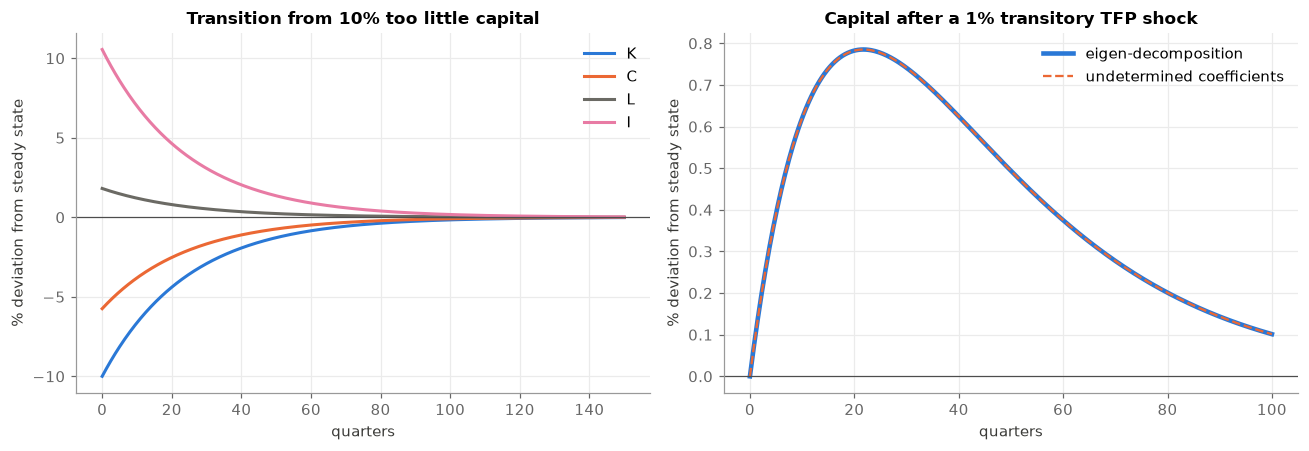

In [7]:
path = rbc.irf(p, k0=-0.10, T=37.5, n=601)   # time in years; plotted in quarters
shock = rbc.irf(p, z0=0.01, theta_z=theta, T=25, n=401)
t = shock.index.values
k_policy = 100 * pc["nu_kz"] * 0.01 / (pc["mu_s"] + theta) * (np.exp(pc["mu_s"] * t) - np.exp(-theta * t))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for v, col in [("K", COLORS["gdp"]), ("C", COLORS["series"]), ("L", COLORS["trend"]), ("I", "#e87ba4")]:
    axes[0].plot(4 * path.index, path[v], color=col, lw=2, label=v)
axes[0].axhline(0, color="0.3", lw=0.8)
axes[0].set_xlabel("quarters"); axes[0].set_ylabel("% deviation from steady state")
axes[0].set_title("Transition from 10% too little capital"); axes[0].legend()

axes[1].plot(4 * t, shock["K"], color=COLORS["gdp"], lw=3, label="eigen-decomposition")
axes[1].plot(4 * t, k_policy, color=COLORS["series"], lw=1.5, ls="--", label="undetermined coefficients")
axes[1].axhline(0, color="0.3", lw=0.8)
axes[1].set_xlabel("quarters"); axes[1].set_ylabel("% deviation from steady state")
axes[1].set_title("Capital after a 1% transitory TFP shock"); axes[1].legend()
plt.tight_layout()
print(f"max difference between the two solutions: {np.abs(shock['K'] - k_policy).max():.1e}")

## 9. Checking the linear solution against the nonlinear model

The linearization is only a local approximation. We can compute the exact perfect-foresight transition of the *nonlinear* model. Combining labor supply from (HH-FOC) with labor demand (LD) gives the labor market condition $L_t^{1/\eta} = \lambda_t(1-\alpha)Z_tK_t^\alpha L_t^{-\alpha}$. Solving it for hours,

$$
L_t = \left[ \lambda_t (1-\alpha) Z_t K_t^\alpha \right]^{\frac{1}{1/\eta + \alpha}} \equiv L(K_t,\lambda_t,Z_t),
$$

and substituting into capital accumulation (KA) (with $I_t = Y_t - C_t$) and the co-state equation in (HH-FOC), the equilibrium reduces to two nonlinear differential equations in $(K_t, \lambda_t)$:

$$
\begin{aligned}
\dot K_t &= Z_t K_t^\alpha L(K_t,\lambda_t,Z_t)^{1-\alpha} - \frac{1}{\lambda_t} - \delta K_t, \\
\dot \lambda_t &= \lambda_t\left(\rho + \delta - \alpha Z_t K_t^{\alpha - 1} L(K_t,\lambda_t,Z_t)^{1-\alpha}\right).
\end{aligned}
$$

These are `rbc.labor` and `rbc.rhs` in the code. We solve them as a two-point boundary value problem: $K_0$ is given by the steady state, and $\lambda_{\mathcal T}$ must equal its steady-state value at some distant horizon $\mathcal T$ (`rbc.nonlinear_path`, using `scipy.integrate.solve_bvp`). The figure compares the linear and nonlinear solutions for a transitory productivity shock of 1% and of 10%.

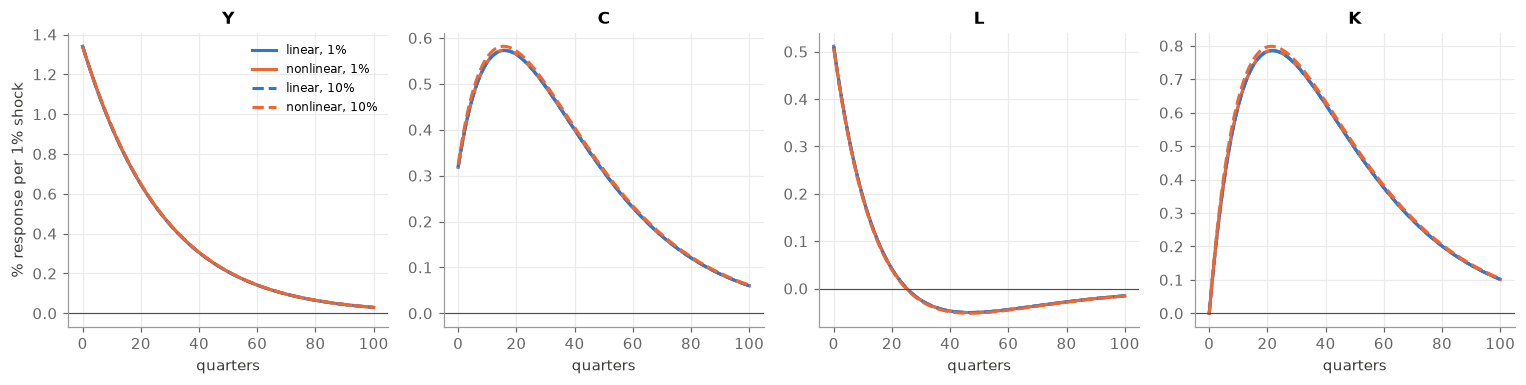

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for size, ls in [(0.01, "-"), (0.10, "--")]:
    lin = rbc.irf(p, z0=size, theta_z=theta, T=25, n=401)
    nl, ss0 = rbc.nonlinear_path(p, Zpath=lambda t: np.exp(size * np.exp(-theta * t)), T=75, n=1201)
    nl = nl.loc[:25]
    for ax, v in zip(axes, ["Y", "C", "L", "K"]):
        ax.plot(4 * lin.index, lin[v] / (100 * size), color=COLORS["gdp"], lw=2, ls=ls, label=f"linear, {size:.0%}")
        ax.plot(4 * nl.index, np.log(nl[v] / ss0[v]) / size, color=COLORS["series"], lw=2, ls=ls,
                label=f"nonlinear, {size:.0%}")
        ax.set_title(v); ax.axhline(0, color="0.3", lw=0.7); ax.set_xlabel("quarters")
axes[0].set_ylabel("% response per 1% shock")
axes[0].legend(fontsize=8)
plt.tight_layout()

Responses are scaled by the size of the shock. For a 1% shock the linear and nonlinear paths are indistinguishable. For a 10% shock, which is very large by business cycle standards, the differences are still small. The linearized model is an excellent guide to the dynamics of the RBC model at business cycle frequencies.

## 10. Try it yourself

1. **Steady state.** How do $\bar K/\bar Y$, $\bar C/\bar Y$ and $\bar L$ change with $\rho$, $\delta$ and $\eta$? Explain intuitively.
2. **Inelastic labor.** Set $\eta \to 0$ (e.g. `eta=1e-6`), so hours are fixed. Derive $A$, $b$ and $\nu_{\lambda k}$ by hand for this case and compare with our solution $\eta=1$. Can you explain intutively why they look different?
4. **Speed of convergence.** How does the half-life of the capital gap depend on $\delta$, $\alpha$, and $\eta$? Explain intuitively and use `rbc.saddle(rbc.linear_system(p)[0])` to verify your answer.
5. **Persistence.** How do $\nu_{\lambda z}$ and $\nu_{kz}$ depend on $\theta$? Use `rbc.policy_coefficients(p, theta)` for $\theta$ between 0 (permanent) and 2 (a half-life of about four months).
6. **Blanchard–Kahn.** Suppose, incorrectly, that consumption were predetermined and could not jump. How many state variables and unstable eigenvalues would the system have? What would happen?